# 01 — Dataset Exploration
How do we distinguish an unseen test image, a reference image, and a defect mask in MVTec AD? This notebook inspects the official DTU copy directly. Set the dataset path with the MVTEC_ROOT environment variable if running elsewhere.

This notebook requires the official MVTec AD dataset. The remaining four notebooks use archived results and do not require dataset images or GPU inference.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
import os
from PIL import Image, ImageOps, ImageDraw
data = Path(os.environ.get("MVTEC_ROOT", "/work3/s183356/datasets/mvtec_official")).expanduser()
if not data.is_dir():
    raise FileNotFoundError(f"MVTec AD not found at {data}. Set MVTEC_ROOT to the official extracted dataset directory.")

## Verify the splits and mask pairing
A normal training image can enter the reference bank. Each defective test image has a mask with the same stem plus the suffix _mask; normal test images are evaluated with an all-zero mask.

In [2]:
rows = []
for category in sorted(p for p in data.iterdir() if (p / "test").is_dir()):
    train = sorted((category / "train").glob("*/*.png"))
    test = sorted((category / "test").glob("*/*.png"))
    defective = [p for p in test if p.parent.name != "good"]
    expected = {category / "ground_truth" / p.parent.name / (p.stem + "_mask.png") for p in defective}
    assert set((category / "ground_truth").glob("*/*.png")) == expected
    assert all(p.parent.name == "good" for p in train)
    rows.append([category.name, len(train), len(test) - len(defective), len(defective), len(expected)])
counts = pd.DataFrame(rows, columns=["category", "train_good", "test_good", "test_defective", "masks"]).set_index("category")
assert len(counts) == 15
assert counts.sum().tolist() == [3629, 467, 1258, 1258]
display(pd.concat([counts, counts.sum().to_frame("Total").T]))

,train_good,test_good,test_defective,masks
bottle,209,20,63,63
cable,224,58,92,92
capsule,219,23,109,109
carpet,280,28,89,89
grid,264,21,57,57
hazelnut,391,40,70,70
leather,245,32,92,92
metal_nut,220,22,93,93
pill,267,26,141,141
screw,320,41,119,119


## One bottle, three roles
The training image establishes normal appearance. The test image is scored without its mask; the mask is used afterwards to evaluate localization. White mask pixels denote the annotated defect.

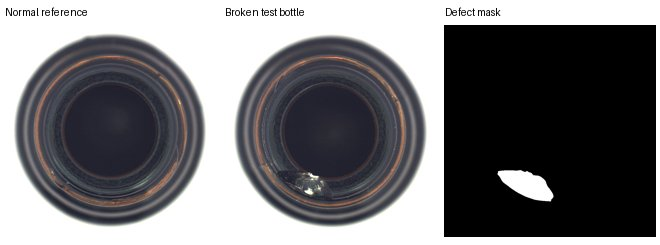

In [3]:
from io import BytesIO
from IPython.display import Image as NotebookImage

example = data / "bottle"
panels = [("Normal reference", example / "train/good/000.png"),
          ("Broken test bottle", example / "test/broken_small/009.png"),
          ("Defect mask", example / "ground_truth/broken_small/009_mask.png")]
canvas = Image.new("RGB", (660, 245), "white")
draw = ImageDraw.Draw(canvas)
for index, (label, path) in enumerate(panels):
    with Image.open(path) as source:
        tile = ImageOps.contain(source.convert("RGB"), (212, 212))
    canvas.paste(tile, (220 * index + 4, 25))
    draw.text((220 * index + 5, 6), label, fill="black")
buffer = BytesIO()
canvas.save(buffer, format="JPEG", quality=85)
display(NotebookImage(data=buffer.getvalue()))

Images and masks: [MVTec AD](https://www.mvtec.com/research-teaching/datasets/mvtec-ad), MVTec Software GmbH, CC BY-NC-SA 4.0. The figure contains resized, labeled examples. See the [dataset verification record](../research_logs/MVTec_AD_dataset.md).